# Combustibles y baseline de Madre de Dios

**Sprint 4 · Task 2.2 · Diego Miranda y Gael**

La grilla focal tiene 10 000 celdas. Partimos del archivo de vegetación de Diego y de la máscara de Jack. Primero revisamos qué combustible recibe cada celda y luego ejecutamos el motor con ambos modelos.

**Colab.** Abre este cuaderno y ejecuta todas las celdas. Si aún no está el proyecto en la sesión, selecciona el ZIP de esta entrega cuando se abra el selector. En una instalación local, abre el cuaderno desde la carpeta descomprimida.

In [1]:
from pathlib import Path
import sys
import zipfile

def tiene_proyecto(ruta):
    return (ruta / "src/data/combustibles.py").is_file() and (ruta / "docs/tabla_combustibles_mdd.csv").is_file()

actual = Path.cwd()
raiz = next((p for p in (actual, *actual.parents) if tiene_proyecto(p)), None)
if raiz is None:
    from google.colab import files
    print("Selecciona Sprint4_Task22_Diego_Gael.zip")
    nombre = next(iter(files.upload()))
    raiz = actual / "proyecto_task22"
    with zipfile.ZipFile(nombre) as archivo:
        archivo.extractall(raiz)
    if not tiene_proyecto(raiz):
        raise ValueError("Este ZIP no contiene los archivos de la Task 2.2")
sys.path.insert(0, str(raiz))

# Algunas sesiones de Colab vienen sin el lector de GeoTIFF.
from importlib.util import find_spec
if find_spec("rasterio") is None:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])

import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from src.data.combustibles import TABLA, crear_mapa_combustibles
from src.calibration.madre_de_dios import DATOS, cargar_escenario_mdd
from src.calibration import calcular_iou, funcion_objetivo, simular_replica

carpeta = DATOS / "processed"
salidas = raiz / "docs/resultados_task_2_2"
salidas.mkdir(parents=True, exist_ok=True)

## Cobertura y combustible

El raster conserva los códigos de Dynamic World. Para la clase 6 contamos los ocho vecinos de cada celda. Marcamos como borde las que tienen al menos dos vecinos con vegetación. La regla se aplica una sola vez sobre las clases originales.

In [2]:
with rasterio.open(carpeta / "madre_de_dios_vegetacion_100m.tif") as raster:
    clases = raster.read(1, masked=True).filled(255)
    print(raster.crs, clases.shape, raster.res)
mapa = crear_mapa_combustibles(clases)
base = cargar_escenario_mdd()
observada = base.mascara_observada
tabla = pd.read_csv(TABLA)
filas = []
for fila in tabla.itertuples():
    celdas = clases == fila.clase_dw
    if fila.condicion == "borde":
        celdas = mapa.mascara_construido_borde
    elif fila.condicion == "interior":
        celdas = mapa.mascara_construido_interior
    filas.append([fila.clase_dw, fila.cobertura, fila.condicion, int(celdas.sum()),
                  celdas.mean() * 100, int((celdas & observada).sum())])
cobertura = pd.DataFrame(filas, columns=["DW", "cobertura", "regla", "celdas", "porcentaje", "en_huella"])
assert cobertura.celdas.sum() == clases.size
cobertura.to_csv(salidas / "cobertura.csv", index=False, float_format="%.2f")
display(cobertura.round(2))

EPSG:32719 (100, 100) (100.0, 100.0)


,DW,cobertura,regla,celdas,porcentaje,en_huella
0,0,Agua,todas,130,1.30,0
1,1,Árboles,todas,6641,66.41,31
2,2,Pasto,todas,1186,11.86,2
3,3,Vegetación inundada,todas,0,0.00,0
4,4,Cultivos,todas,315,3.15,0
5,5,Matorral,todas,991,9.91,6
6,6,Construido,borde,472,4.72,12
7,6,Construido,interior,254,2.54,1
8,7,Suelo desnudo,todas,11,0.11,0
9,8,Nieve y hielo,todas,0,0.00,0


In [3]:
focos = pd.read_csv(carpeta / "madre_de_dios_firms_100m.csv")
r, c = focos.grid_row, focos.grid_col
focos["DW"] = clases[r, c]
focos["vecinos_vegetales"] = mapa.vecinos_combustibles[r, c]
focos["codigo_prop"] = mapa.tipo_combustible[r, c]
focos["borde_construido"] = mapa.mascara_construido_borde[r, c]
focos["ignicion_inicial"] = [(i, j) in base.focos_iniciales for i, j in zip(r, c)]
focos = focos[["fire_id", "acq_date", "acq_time", "grid_row", "grid_col", "DW",
               "vecinos_vegetales", "codigo_prop", "borde_construido", "ignicion_inicial"]]
focos.to_csv(salidas / "focos_clasificados.csv", index=False)
display(focos)

,fire_id,acq_date,acq_time,grid_row,grid_col,DW,vecinos_vegetales,codigo_prop,borde_construido,ignicion_inicial
0,FIRMS-MDD-2024-0001,2024-08-14,1805,23,81,1,8,1,False,True
1,FIRMS-MDD-2024-0014,2024-08-17,1849,50,53,1,8,1,False,False
2,FIRMS-MDD-2024-0016,2024-08-18,1831,76,64,1,8,1,False,False
3,FIRMS-MDD-2024-0017,2024-08-18,1831,35,82,6,5,6,True,False
4,FIRMS-MDD-2024-0018,2024-08-18,1831,33,81,6,2,6,True,False
5,FIRMS-MDD-2024-0019,2024-08-18,1831,26,17,6,5,6,True,False


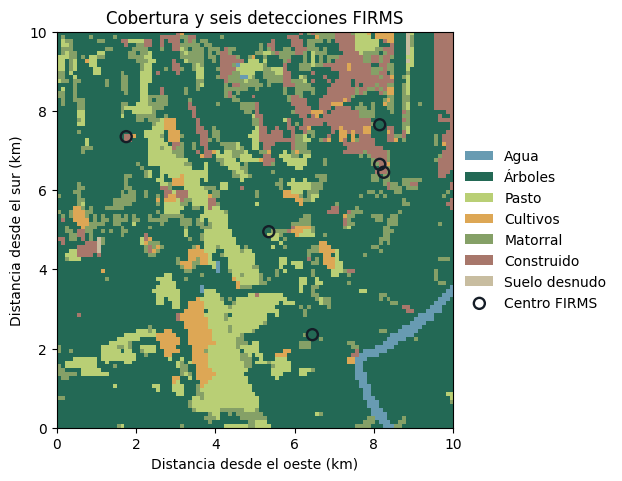

In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

paleta = ["#689bb2", "#236955", "#b9cf75", "#7aa59b", "#dda755", "#85a067",
          "#a8776b", "#c8bda0", "#e7f2f7"]
fig, ax = plt.subplots(figsize=(6.5, 4.7), layout="constrained")
ax.imshow(clases, cmap=ListedColormap(paleta), norm=BoundaryNorm(np.arange(-0.5, 9), 9),
          interpolation="nearest", extent=(0, 10, 0, 10))
ax.scatter((c + 0.5) / 10, (99.5 - r) / 10, s=63, marker="o", facecolors="none",
           edgecolors="#151d27", linewidths=1.7, label="Centro FIRMS")
ax.set(xlabel="Distancia desde el oeste (km)", ylabel="Distancia desde el sur (km)",
       title="Cobertura y seis detecciones FIRMS")
leyenda = [Patch(facecolor=paleta[int(j)], label=tabla.loc[tabla.clase_dw == j, "cobertura"].iloc[0])
           for j in np.unique(clases) if j != 255]
ax.legend(handles=leyenda + [ax.collections[0]], loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
fig.savefig(salidas / "cobertura_focal.png", dpi=160)
plt.show()

## Sensibilidad del borde construido

Contamos cuántas celdas admite cada regla y cuántas caen dentro de la huella de 52 ha. Este cruce describe la compatibilidad espacial. Las mismas detecciones motivaron revisar el borde, por lo que no sirven como validación independiente de la regla.

In [5]:
vegetales = (mapa.factor_flamabilidad > 0) & (clases != 6)
filas = []
for nombre, umbral in [("Barrera total", None), ("1 vecino", 1), ("2 vecinos", 2), ("3 vecinos", 3)]:
    borde = np.zeros_like(clases, dtype=bool) if umbral is None else (clases == 6) & (mapa.vecinos_combustibles >= umbral)
    admitidas = vegetales | borde
    filas.append([nombre, borde.sum(), admitidas[r, c].sum(), (admitidas & observada).sum()])
sensibilidad = pd.DataFrame(filas, columns=["regla", "celdas_de_borde", "centros_admitidos", "celdas_admitidas_en_huella"])
sensibilidad.to_csv(salidas / "sensibilidad_borde.csv", index=False)
display(sensibilidad)

,regla,celdas_de_borde,centros_admitidos,celdas_admitidas_en_huella
0,Barrera total,0,3,39
1,1 vecino,564,6,52
2,2 vecinos,472,6,51
3,3 vecinos,391,5,49


## Línea base y entrada a calibración

Partimos del primer foco a las 18:05 UTC del 14 de agosto. El último pasó a las 18:31 del día 18. Representamos ambos instantes por su hora entera y usamos los 96 intervalos de viento entre ellos. El reloj adopta un paso por hora como supuesto del modelo. Los cinco focos posteriores quedan solo en la referencia.

Usamos los parámetros iniciales del evaluador y las mismas 10 semillas en ambos modelos. El IoU divide la intersección de las dos máscaras entre su unión. El error de área se calcula por réplica como 100 × |área simulada − área de referencia| / área de referencia.

In [6]:
from src.calibration import normalizar_parametros

filas = []
for modo in ["base", "propagator"]:
    escenario = cargar_escenario_mdd(modo)
    parametros = normalizar_parametros({}, modo)
    area_ref = observada.sum() * escenario.area_celda_ha
    for semilla in escenario.semillas:
        quemada = simular_replica(parametros, escenario, semilla)
        area = quemada.sum() * escenario.area_celda_ha
        filas.append([modo, semilla, area_ref, area, calcular_iou(quemada, observada),
                      100 * abs(area - area_ref) / area_ref])
replicas = pd.DataFrame(filas, columns=["modo", "semilla", "referencia_ha", "area_ha", "IoU", "error_area_pct"])
replicas.to_csv(salidas / "replicas.csv", index=False)
resumen = replicas.groupby("modo")[["area_ha", "IoU", "error_area_pct"]].agg(["mean", "std"])
resumen.columns = ["_".join(columna) for columna in resumen.columns]
resumen.to_csv(salidas / "resumen.csv")
display(resumen.round(5))
print("Desviación estándar muestral calculada con las diez semillas (ddof=1).")

Desviación estándar muestral calculada con las diez semillas (ddof=1).


,area_ha_mean,area_ha_std,IoU_mean,IoU_std,error_area_pct_mean,error_area_pct_std
modo,,,,,,
base,7098.6,310.30136,0.00718,0.00031,13551.15385,596.73338
propagator,7375.5,391.46058,0.00686,0.00040,14083.65385,752.80882


In [7]:
# Una llamada real a la función que puede minimizar el optimizador.
# m6 modifica solo el borde de la fórmula base. PROPAGATOR usa el código del combustible.
for modo in ["base", "propagator"]:
    escenario = cargar_escenario_mdd(modo)
    perdida = funcion_objetivo({}, escenario=escenario)
    assert np.isclose(perdida, 1 - resumen.loc[modo, "IoU_mean"])
    print(f"{modo}: pérdida inicial = {perdida:.6f}")

base: pérdida inicial = 0.992819
propagator: pérdida inicial = 0.993136


## Evolución de una réplica

La animación toma una imagen cada 12 pasos de la semilla 42. El contorno rojo marca la huella VIIRS acumulada. Las zonas oscuras muestran el área acumulada que alcanzó la fórmula base.

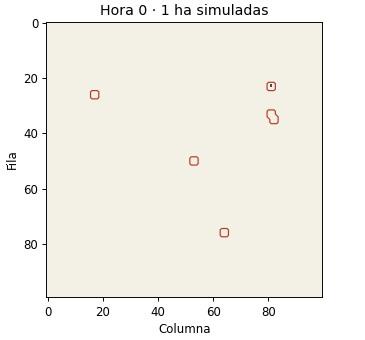

In [8]:
from dataclasses import replace
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

inicial = np.zeros_like(observada)
for fila, col in base.focos_iniciales:
    inicial[fila, col] = True
pasos = list(range(0, base.pasos_simulacion + 1, 12))
cuadros = [inicial] + [simular_replica({}, replace(base, pasos_simulacion=p), 42) for p in pasos[1:]]
fig, ax = plt.subplots(figsize=(4.3, 4), layout="constrained")
colores = ListedColormap(["#f3f1e5", "#37594a"])
imagen = ax.imshow(inicial, cmap=colores, vmin=0, vmax=1, interpolation="nearest")
ax.contour(observada, levels=[0.5], colors="#b83923", linewidths=1)
ax.set(xlabel="Columna", ylabel="Fila")
def dibujar(i):
    imagen.set_data(cuadros[i])
    ax.set_title(f"Hora {pasos[i]} · {cuadros[i].sum()} ha simuladas")
    return imagen,

gif = salidas / "baseline_semilla42.gif"
animacion = FuncAnimation(fig, dibujar, frames=len(pasos), interval=650)
animacion.save(gif, writer=PillowWriter(fps=1.5), dpi=85)
plt.close(fig)
display(Image(filename=str(gif)))

La comparación mide coincidencia con una huella aproximada. El área crece varios miles de hectáreas en las corridas iniciales, mientras la referencia ocupa 52 ha. El siguiente contraste científico requiere ajustar el modelo y evaluarlo con datos independientes. Las fuentes y las decisiones de equivalencia están en `docs/tabla_combustibles_dynamic_world.md`.